# Logistic regression for pumpkin color and breast-cancer data

This notebook keeps every pumpkin row with a known color, uses train-only preprocessing for a multiclass model, and then applies a separate standardized logistic model to Scikit-learn's breast-cancer dataset.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.datasets import load_breast_cancer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## Multiclass pumpkin color model

Rows are removed only when the target color is unknown. Feature columns are removed only when they are entirely empty or explicitly unnamed; all other missing feature values are left for the training pipeline to impute.

In [2]:
data_path = Path("../../../2-Regression/data/US-pumpkins.csv")
assert data_path.is_file(), f"Missing dataset: {data_path.resolve()}"

raw_pumpkins = pd.read_csv(data_path)
pumpkins = raw_pumpkins.loc[raw_pumpkins["Color"].notna()].copy()
dates = pd.to_datetime(pumpkins["Date"], format="%m/%d/%y", errors="coerce")
pumpkins["Year"] = dates.dt.year
pumpkins["Month"] = dates.dt.month
pumpkins["DayOfYear"] = dates.dt.dayofyear

discarded_fields = [
    column
    for column in pumpkins.columns
    if column.startswith("Unnamed") or pumpkins[column].isna().all()
]
X_pumpkin = pumpkins.drop(columns=["Color", "Date", *discarded_fields])
y_pumpkin = pumpkins["Color"]

assert len(pumpkins) == 1141
assert set(y_pumpkin.unique()) == {"ORANGE", "STRIPED", "WHITE"}
assert "Color" not in X_pumpkin.columns
assert not any(column.startswith("Unnamed") for column in X_pumpkin.columns)
assert not X_pumpkin.isna().all().any()
print("Retained rows:", len(pumpkins))
print("Discarded empty/unnamed fields:", discarded_fields)
y_pumpkin.value_counts().rename_axis("Color").to_frame("Rows")

Retained rows: 1141
Discarded empty/unnamed fields: ['Grade', 'Environment', 'Quality', 'Condition', 'Appearance', 'Storage', 'Crop', 'Trans Mode', 'Unnamed: 24', 'Unnamed: 25']


,Rows
Color,
ORANGE,916
WHITE,213
STRIPED,12


In [3]:
numeric_features = X_pumpkin.select_dtypes(include="number").columns.tolist()
categorical_features = X_pumpkin.select_dtypes(exclude="number").columns.tolist()
preprocessing_features = set(numeric_features) | set(categorical_features)
assert preprocessing_features == set(X_pumpkin.columns)
assert "Color" not in preprocessing_features

numeric_pipeline = Pipeline(
    [
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]
)
categorical_pipeline = Pipeline(
    [
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]
)
preprocessor = ColumnTransformer(
    [
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ]
)
pumpkin_model = Pipeline(
    [
        ("preprocess", preprocessor),
        ("classifier", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42)),
    ]
)

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X_pumpkin, y_pumpkin, test_size=0.2, random_state=42, stratify=y_pumpkin
)
pumpkin_model.fit(X_train, y_train)
pumpkin_predictions = pumpkin_model.predict(X_test)
pumpkin_classes = pumpkin_model.named_steps["classifier"].classes_
pumpkin_accuracy = accuracy_score(y_test, pumpkin_predictions)
pumpkin_macro_f1 = f1_score(y_test, pumpkin_predictions, average="macro")
pumpkin_matrix = confusion_matrix(y_test, pumpkin_predictions, labels=pumpkin_classes)

scaler = (
    pumpkin_model.named_steps["preprocess"]
    .named_transformers_["numeric"]
    .named_steps["scale"]
)
assert scaler.n_samples_seen_ == len(X_train)
assert pumpkin_model.named_steps["classifier"].n_iter_.max() < 2000
assert np.isfinite([pumpkin_accuracy, pumpkin_macro_f1]).all()
print(f"Accuracy: {pumpkin_accuracy:.4f}")
print(f"Macro F1: {pumpkin_macro_f1:.4f}")
print(classification_report(y_test, pumpkin_predictions, zero_division=0))
pd.DataFrame(pumpkin_matrix, index=pumpkin_classes, columns=pumpkin_classes)

Accuracy: 0.8646
Macro F1: 0.6875
              precision    recall  f1-score   support

      ORANGE       0.99      0.85      0.91       184
     STRIPED       0.25      1.00      0.40         2
       WHITE       0.62      0.93      0.75        43

    accuracy                           0.86       229
   macro avg       0.62      0.93      0.69       229
weighted avg       0.92      0.86      0.88       229



,ORANGE,STRIPED,WHITE
ORANGE,156,4,24
STRIPED,0,2,0
WHITE,1,2,40


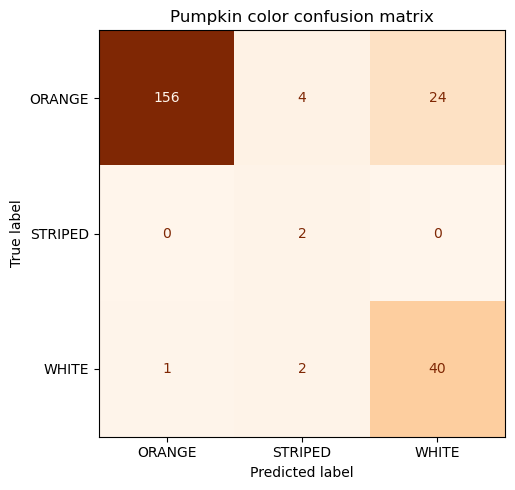

In [5]:
fig, axis = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(
    confusion_matrix=pumpkin_matrix, display_labels=pumpkin_classes
).plot(ax=axis, cmap="Oranges", colorbar=False)
axis.set_title("Pumpkin color confusion matrix")
plt.tight_layout()
plt.show()

The model performs well on orange and white pumpkins, but only two striped examples reach the test set. Balanced weights help the rare class influence training, while macro F1 prevents the orange majority from dominating the summary. The striped result is too data-poor to treat as reliable.

## Challenge — breast-cancer classification

Malignant is encoded as the positive class. Standardization is fit inside the pipeline on training rows only; accuracy, positive-class F1, ROC AUC, and the confusion matrix are evaluated on one stratified test split.

In [6]:
cancer = load_breast_cancer(as_frame=True)
X_cancer = cancer.data
y_malignant = (cancer.target == 0).astype(int)
X_train, X_test, y_train, y_test = train_test_split(
    X_cancer, y_malignant, test_size=0.25, random_state=42, stratify=y_malignant
)
cancer_model = Pipeline(
    [
        ("scale", StandardScaler()),
        ("classifier", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=42)),
    ]
)
cancer_model.fit(X_train, y_train)
cancer_predictions = cancer_model.predict(X_test)
cancer_probabilities = cancer_model.predict_proba(X_test)[:, 1]
cancer_metrics = pd.Series(
    {
        "Accuracy": accuracy_score(y_test, cancer_predictions),
        "Malignant F1": f1_score(y_test, cancer_predictions),
        "ROC AUC": roc_auc_score(y_test, cancer_probabilities),
    }
)
cancer_matrix = confusion_matrix(y_test, cancer_predictions, labels=[0, 1])
assert cancer_model.named_steps["scale"].n_samples_seen_ == len(X_train)
assert cancer_model.named_steps["classifier"].n_iter_.max() < 2000
assert np.isfinite(cancer_metrics.to_numpy()).all()
print(cancer_metrics.round(4).to_string())
pd.DataFrame(cancer_matrix, index=["Benign", "Malignant"], columns=["Benign", "Malignant"] )

Accuracy        0.9720
Malignant F1    0.9615
ROC AUC         0.9950


,Benign,Malignant
Benign,89,1
Malignant,3,50


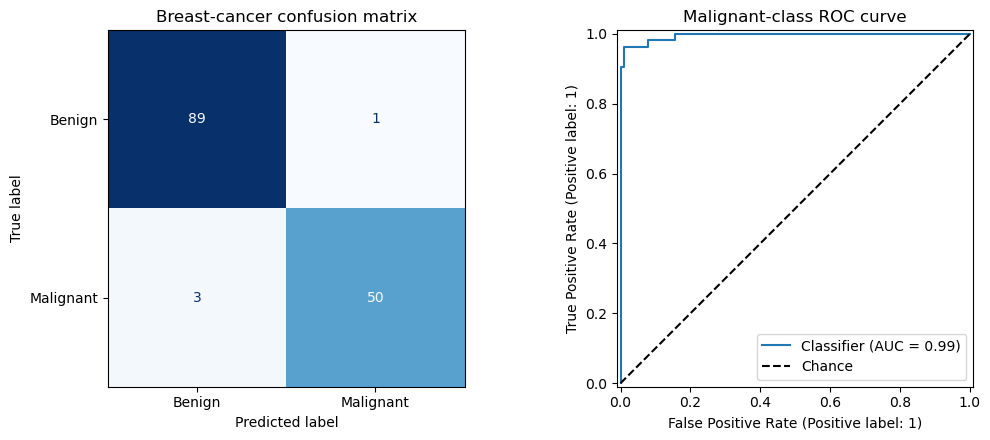

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay(
    confusion_matrix=cancer_matrix, display_labels=["Benign", "Malignant"]
).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Breast-cancer confusion matrix")
RocCurveDisplay.from_predictions(y_test, cancer_probabilities, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Chance")
axes[1].set_title("Malignant-class ROC curve")
axes[1].legend(loc="lower right")
fig.tight_layout()
plt.show()

## Limitations

The pumpkin data is highly imbalanced and reflects market-report practices, not controlled color sampling. The breast-cancer dataset is small and curated, and a single random split does not measure uncertainty or external validity. Its three missed malignant cases matter more than the headline accuracy. These models demonstrate a workflow; they are not deployment or medical-decision systems.